# Juros, spreads e inadimplência no crédito brasileiro (2011–2026): como pessoas físicas e jurídicas, modalidades, estados e portes se comportam, e como o crédito responde à Selic

**Autores:** Abner Blota, Frederico Taveira e João Vitor Maia Prates
**Disciplina:** Análise Exploratória de Dados e Visualização, FGV EMAp, 2026.2
**Repositório:** https://github.com/JoaoVitor2108/Projeto-AEDV

---

## Introdução

### Problema

Quando o Banco Central muda a taxa Selic, o efeito não chega do mesmo jeito a todo o crédito. Uma empresa grande, uma família de baixa renda, um estado do Norte e um estado do Sudeste enfrentam custos diferentes, e a proporção de empréstimos que deixam de ser pagos também difere. Este trabalho investiga como o **custo do crédito** (medido pelo spread, a diferença entre a taxa cobrada dos clientes e o custo de captação dos bancos) e a **inadimplência** (carteira com atraso superior a 90 dias) evoluíram de 2011 a 2026, e como variam entre:

- pessoas físicas e pessoas jurídicas
- tipos de crédito (cartão, cheque especial, crédito pessoal, financiamentos etc.)
- estados
- faixas de renda (para pessoas físicas) e portes de empresa (para pessoas jurídicas)

e como a inadimplência e o spread respondem às mudanças da Selic, em tempo e em intensidade.

### Contexto

O período estudado cobre eventos que mexeram com o crédito: ciclos fortes de alta e de queda da Selic, a pandemia de covid-19 e a recuperação que veio depois. Nos últimos anos, a inadimplência das pessoas físicas na série do Banco Central chega ao fim do período, em agosto de 2026, em 6,03% da carteira, o maior valor de toda a série analisada, que começa em 2011.

Usamos dados públicos do Banco Central (séries do SGS e a base SCR.data, que detalha a carteira de crédito por estado, tipo de cliente, porte e modalidade). A base SCR.data começa em julho de 2012, e as séries do SGS, em março de 2011 (a Selic, em janeiro de 2011).

### Motivação

A inadimplência e o custo do crédito afetam diretamente o orçamento das famílias, a sobrevivência de empresas e a política monetária. Médias nacionais escondem diferenças grandes: um número único para "a inadimplência no Brasil" não diz quem está pagando mais caro, quem está deixando de pagar, nem se a política de juros chega do mesmo jeito a todos. Olhar os recortes (tipo de cliente, produto, região, renda e porte) permite ver onde estão os problemas e como eles mudaram, e testar se a resposta à Selic é rápida ou lenta, igual na alta e na queda.

### Perguntas

1. Como evoluiu a inadimplência de pessoas físicas e jurídicas desde 2011?
2. Quais modalidades de crédito têm mais inadimplência, e esse ranking é estável ao longo do tempo?
3. O spread de pessoas físicas é sistematicamente diferente do de pessoas jurídicas, e essa diferença mudou?
4. A inadimplência varia entre os estados?
5. Quanto tempo a inadimplência demora para reagir a mudanças na Selic, e isso depende da modalidade?
6. O spread acompanha a Selic de forma simétrica, sobe tanto na alta quanto cai na queda?
7. Faixas de renda mais baixas e empresas menores são mais sensíveis aos juros?
8. A pandemia mudou de forma duradoura a inadimplência de cada modalidade?

### Organização do notebook

1. **Dados:** fontes, obtenção, tratamento e conferências
2. **Perguntas:** uma seção por pergunta, com transformação, visualização e análise
3. **Conclusão:** síntese, recomendações e limitações

In [1]:
import pandas as pd
import requests
from pathlib import Path
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import numpy as np

---

# Bloco 1: Aquisição dos Dados e Análise Exploratória

### Inadimplência de pessoas físicas (SGS 21084)

Baixamos a série mensal de inadimplência da carteira de pessoas físicas pela API do Banco Central.
A API devolve erro 502 quando pedimos a série sem datas, então sempre informamos `dataInicial` e `dataFinal`.

- **Definição:** carteiras com atraso superior a 90 dias
- **Unidade:** percentual


Conferência: vieram 186 registros, de mar/2011 a ago/2026, que é o número esperado de meses.

In [2]:
#Criaremos essa funcao pois as proximas series utilizarao essa mesma funcao para baixar os dados
def baixar_sgs(codigo, inicio="01/01/2011", fim="31/08/2026"):
    url = f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo}/dados?formato=json&dataInicial={inicio}&dataFinal={fim}"
    resposta = requests.get(url, timeout=60)
    resposta.raise_for_status()
    return pd.DataFrame(resposta.json())

In [3]:
inad_pf_api = baixar_sgs(21084)
print(inad_pf_api.shape)
inad_pf_api.head()

(186, 2)


,data,valor
0,01/03/2011,4.62
1,01/04/2011,4.67
2,01/05/2011,4.82
3,01/06/2011,4.79
4,01/07/2011,4.90


### Criamos um arquivo csv para salvar os dados devido a instabilidade da api do banco central, e daqui em diante usaremos esse arquivo como base para o data frame

In [4]:
Path("data/sgs").mkdir(parents=True, exist_ok=True)
inad_pf_api.to_csv("data/sgs/inad_pf_21084.csv", index=False)

In [5]:
inad_pf = pd.read_csv("data/sgs/inad_pf_21084.csv")
print(inad_pf.shape)
inad_pf.dtypes

(186, 2)


data         str
valor    float64
dtype: object

### Vamos fazer a conversão dos tipos a fim de ter as datas como data e não string

In [6]:
inad_pf["data"] = pd.to_datetime(inad_pf["data"], format="%d/%m/%Y")
inad_pf.dtypes

data     datetime64[us]
valor           float64
dtype: object

#### Vamos fazer uma análise geral dos dados, para termos uma noção das linhas com valores nulos, o shape do data frame e medidas estatísticas

In [7]:
print(inad_pf.shape)
print(inad_pf["data"].min(), inad_pf["data"].max())
print(inad_pf["valor"].describe())
print(inad_pf.isna().sum())

(186, 2)
2011-03-01 00:00:00 2026-08-01 00:00:00
count    186.000000
mean       4.100215
std        0.698277
min        2.890000
25%        3.655000
50%        4.000000
75%        4.367500
max        6.030000
Name: valor, dtype: float64
data     0
valor    0
dtype: int64


## Inadimplência de pessoas jurídicas (SGS 21083)

Mesma definição e unidade da série de pessoas físicas: percentual da carteira com atraso superior a 90 dias. Usamos o mesmo período para que as duas séries possam ser comparadas mês a mês. Vamos utilizar a mesma estrutura de código para fazer a análise dos dados, para facilitar o entendimento 

In [8]:
inad_pj_api = baixar_sgs(21083)
print(inad_pj_api.shape)
inad_pj_api.head()

(186, 2)


,data,valor
0,01/03/2011,1.96
1,01/04/2011,2.04
2,01/05/2011,2.15
3,01/06/2011,2.09
4,01/07/2011,2.18


In [9]:
inad_pj_api.to_csv("data/sgs/inad_pj_21083.csv", index=False)

In [10]:
inad_pj = pd.read_csv("data/sgs/inad_pj_21083.csv")
print(inad_pj.shape)
inad_pj.dtypes

(186, 2)


data         str
valor    float64
dtype: object

In [11]:
inad_pj["data"] = pd.to_datetime(inad_pj["data"], format="%d/%m/%Y")
inad_pj.dtypes

data     datetime64[us]
valor           float64
dtype: object

In [12]:
print(inad_pj.shape)
print(inad_pj["data"].min(), inad_pf["data"].max())
print(inad_pj["valor"].describe())
print(inad_pj.isna().sum())

(186, 2)
2011-03-01 00:00:00 2026-08-01 00:00:00
count    186.000000
mean       2.414194
std        0.590099
min        1.240000
25%        2.022500
50%        2.395000
75%        2.767500
max        4.060000
Name: valor, dtype: float64
data     0
valor    0
dtype: int64


## Spread de pessoas físicas (SGS 20785)

Spread médio do crédito para pessoas físicas, isto é, a diferença entre a taxa de juros cobrada dos clientes e o custo de captação dos bancos.

- **Definição:** spread médio das operações de crédito de pessoas físicas
- **Unidade:** pontos percentuais

 Vamos utilizar a mesma estrutura de análise utilizada anteriormente, para garantir a coerência

Conferência: esperamos 186 registros, de mar/2011 a ago/2026, como nas séries de inadimplência.

In [13]:
spread_pf_api = baixar_sgs(20785)
print(spread_pf_api.shape)
spread_pf_api.head()

(186, 2)


,data,valor
0,01/03/2011,26.06
1,01/04/2011,26.66
2,01/05/2011,26.49
3,01/06/2011,26.30
4,01/07/2011,26.34


In [14]:
spread_pf_api.to_csv("data/sgs/spread_pf_20785.csv", index=False)

In [15]:
spread_pf = pd.read_csv("data/sgs/spread_pf_20785.csv")
print(spread_pf.shape)
spread_pf.dtypes

(186, 2)


data         str
valor    float64
dtype: object

In [16]:
spread_pf["data"] = pd.to_datetime(spread_pf["data"], format="%d/%m/%Y")
spread_pf.dtypes

data     datetime64[us]
valor           float64
dtype: object

In [17]:
print(spread_pf.shape)
print(spread_pf["data"].min(), spread_pf["data"].max())
print(spread_pf["valor"].describe())
print(spread_pf.isna().sum())

(186, 2)
2011-03-01 00:00:00 2026-08-01 00:00:00
count    186.000000
mean      24.549247
std        3.350309
min       18.590000
25%       21.980000
50%       24.740000
75%       26.560000
max       33.080000
Name: valor, dtype: float64
data     0
valor    0
dtype: int64


## Spread de pessoas jurídicas (SGS 20784)

Mesma definição e unidade da série de pessoas físicas, agora para pessoas jurídicas. Usamos o mesmo período para comparar os dois spreads mês a mês.

- **Definição:** spread médio das operações de crédito de pessoas jurídicas
- **Unidade:** pontos percentuais

Vamos utilizar a mesma estrutura de análise utilizada anteriormente, para garantir a coerência

Conferência: esperamos 186 registros, de mar/2011 a ago/2026.

In [18]:
spread_pj_api = baixar_sgs(20784)
print(spread_pj_api.shape)
spread_pj_api.head()

(186, 2)


,data,valor
0,01/03/2011,10.22
1,01/04/2011,10.72
2,01/05/2011,10.72
3,01/06/2011,10.50
4,01/07/2011,10.39


In [19]:
spread_pj_api.to_csv("data/sgs/spread_pj_20784.csv", index=False)

In [20]:
spread_pj = pd.read_csv("data/sgs/spread_pj_20784.csv")
print(spread_pj.shape)
spread_pj.dtypes

(186, 2)


data         str
valor    float64
dtype: object

In [21]:
spread_pj["data"] = pd.to_datetime(spread_pj["data"], format="%d/%m/%Y")
spread_pj.dtypes

data     datetime64[us]
valor           float64
dtype: object

In [22]:
print(spread_pj.shape)
print(spread_pj["data"].min(), spread_pj["data"].max())
print(spread_pj["valor"].describe())
print(spread_pj.isna().sum())

(186, 2)
2011-03-01 00:00:00 2026-08-01 00:00:00
count    186.000000
mean       9.016720
std        1.363013
min        5.990000
25%        8.155000
50%        8.815000
75%        9.810000
max       12.360000
Name: valor, dtype: float64
data     0
valor    0
dtype: int64


## Taxa Selic meta (SGS 432)

**O que é a Selic.** É a taxa básica de juros da economia brasileira. O Comitê de Política Monetária (Copom) do Banco Central se reúne a cada seis semanas, aproximadamente, e define uma **meta** para ela: pode subir, cair ou ficar igual. Ela serve de referência para o custo do dinheiro no país: quando a Selic sobe, captar recursos fica mais caro para os bancos e, em geral, os juros cobrados de pessoas e empresas também sobem.

**Por que ela entra neste trabalho.** Duas das nossas perguntas dependem de como o crédito responde à Selic:

- **Defasagem (atraso):** os efeitos de uma mudança na Selic não são imediatos. Os juros do crédito se ajustam em semanas, mas a inadimplência demora mais, porque as pessoas e empresas só deixam de pagar depois de meses de parcelas mais caras. Medir a defasagem é estimar quanto tempo passa entre a mudança da Selic e a reação da inadimplência.
- **Simetria:** o spread (a diferença entre a taxa que o cliente paga e o custo de captação do banco) deveria acompanhar a Selic nos dois sentidos. Verificamos se isso acontece, ou seja, se o spread sobe tanto quando a Selic sobe quanto cai quando a Selic cai. Se ele subir rápido e cair devagar, a resposta é **assimétrica**.

**Sobre a série.**

- **Definição:** meta da taxa Selic definida pelo Copom
- **Unidade:** percentual ao ano
- **Frequência:** diária, diferente das outras séries, que são mensais. Como a meta só muda nas reuniões do Copom, o valor se repete por vários dias seguidos.

A série traz registros com datas posteriores ao período das demais, então cortamos em 31/08/2026. Como é diária, o número de registros é bem maior que 186, e mais adiante a convertemos para mensal para poder compará-la com as outras séries.

In [23]:
parte1 = baixar_sgs(432, "01/01/2011", "31/12/2018")
parte2 = baixar_sgs(432, "01/01/2019", "31/08/2026")
selic_api = pd.concat([parte1, parte2], ignore_index=True)
print(selic_api.shape)
selic_api.head()


(5722, 2)


,data,valor
0,01/01/2011,10.75
1,02/01/2011,10.75
2,03/01/2011,10.75
3,04/01/2011,10.75
4,05/01/2011,10.75


In [24]:
selic_api.to_csv("data/sgs/selic_432.csv", index=False)

In [25]:
selic = pd.read_csv("data/sgs/selic_432.csv")
print(selic.shape)
selic.dtypes

(5722, 2)


data         str
valor    float64
dtype: object

In [26]:
selic["data"] = pd.to_datetime(selic["data"], format="%d/%m/%Y")
selic.dtypes

data     datetime64[us]
valor           float64
dtype: object

In [27]:
print(selic.shape)
print(selic["data"].min(), selic["data"].max())
print(selic["valor"].describe())
print(selic.isna().sum())
print(selic["data"].is_unique)

(5722, 2)
2011-01-01 00:00:00 2026-08-31 00:00:00
count    5722.000000
mean       10.110888
std         3.708206
min         2.000000
25%         7.250000
50%        11.000000
75%        13.750000
max        15.000000
Name: valor, dtype: float64
data     0
valor    0
dtype: int64
True


### Selic mensal

As demais séries são mensais e a Selic é diária. Para compará-las, calculamos a **média da meta em cada mês**. A média é uma escolha nossa: como a meta só muda nas reuniões do Copom, ela pesa cada valor pelo número de dias em que esteve em vigor no mês. Datamos cada mês no dia 1, como nas outras séries.

Observação: Ao rodar a célula seguinte, notaremos que temos 188 linhas (ou seja 188 meses), isso mostra que os dados relativos à Selic começam a ser observados 2 meses antes das outras séries. Ao fazer as visualizações e análises, vamos levar isso em consideração

In [28]:
selic_mensal = selic.set_index("data")["valor"].resample("MS").mean().reset_index()
print(selic_mensal.shape)
#A proxima linha faz uma checagem para ver se ao passar a selic para mensal, o periodo de tempo esta compreendido no mesmo das series anteriores
print(inad_pf["data"].isin(selic_mensal["data"]).all())
selic_mensal.head()

(188, 2)
True


,data,valor
0,2011-01-01,10.943548
1,2011-02-01,11.250000
2,2011-03-01,11.717742
3,2011-04-01,11.800000
4,2011-05-01,12.000000


## SCR.data: carteira de crédito por recorte

O SCR.data é a base do Banco Central com os dados do Sistema de Informações de Crédito (SCR). Diferente das séries da SGS, que trazem um número por mês para o país inteiro, aqui a carteira de crédito vem detalhada por estado, tipo de cliente (pessoa física ou jurídica), modalidade, porte e outros recortes. É o que permite responder as perguntas sobre modalidades, estados e porte.

- **Fonte:** arquivos `scrdata_ANO.zip` em `https://www.bcb.gov.br/pda/desig/scrdata_{ANO}.zip`, um ZIP por ano, com um CSV por mês
- **Período:** de jul/2012 em diante (o ZIP de 2012 só tem jul a dez)
- **Tamanho:** cada mês tem cerca de 65 MB (quase 200 mil linhas em jul/2012), e a base inteira passa de 30 milhões de linhas, por isso tratamos um mês por vez

In [29]:
import zipfile
with zipfile.ZipFile("data/raw/scrdata_2012.zip") as z:
    with z.open("scrdata_201207.csv") as f:
        amostra = pd.read_csv(f, sep=";", decimal=",", nrows=1000)

print(amostra.shape)
amostra.dtypes

(1000, 24)


data_base                             str
uf                                    str
segmento                              str
cliente                               str
cnae_ocupacao                         str
porte                                 str
modalidade                            str
submodalidade                         str
origem                                str
indexador                             str
numero_de_operacoes                 int64
a_vencer_ate_90_dias              float64
a_vencer_de_91_ate_360_dias       float64
a_vencer_de_361_ate_1080_dias     float64
a_vencer_de_1081_ate_1800_dias    float64
a_vencer_de_1801_ate_5400_dias    float64
a_vencer_acima_de_5400_dias       float64
carteira_a_vencer                 float64
vencido_de_15_ate_90_dias         float64
vencido_acima_de_90_dias          float64
carteira_vencida                  float64
carteira_ativa                    float64
carteira_inadimplencia            float64
ativo_problematico                

In [30]:
amostra.head()

,data_base,uf,segmento,cliente,cnae_ocupacao,porte,modalidade,submodalidade,origem,indexador,...,a_vencer_de_1081_ate_1800_dias,a_vencer_de_1801_ate_5400_dias,a_vencer_acima_de_5400_dias,carteira_a_vencer,vencido_de_15_ate_90_dias,vencido_acima_de_90_dias,carteira_vencida,carteira_ativa,carteira_inadimplencia,ativo_problematico
0,2012-07-31,AC,Arrendamento,PF,Aposentado/pensionista,Acima de 20 salários mínimos,Operações de arrendamento,Arrendamento financeiro de veículos automotores,Sem destinação específica,Prefixado,...,0.0,0.0,0.0,39890.05,0.00,0.00,0.00,39890.05,0.00,0.00
1,2012-07-31,AC,Arrendamento,PF,Aposentado/pensionista,Acima de 20 salários mínimos,Operações de arrendamento,Arrendamento financeiro exceto veículos automo...,Sem destinação específica,Prefixado,...,0.0,0.0,0.0,39476.56,227.90,0.00,227.90,39704.46,0.00,0.00
2,2012-07-31,AC,Arrendamento,PF,Aposentado/pensionista,Acima de 20 salários mínimos,Outros créditos,Títulos e créditos a receber,Sem destinação específica,Prefixado,...,0.0,0.0,0.0,578.01,0.00,0.00,0.00,578.01,0.00,0.00
3,2012-07-31,AC,Arrendamento,PF,Aposentado/pensionista,Até 1 salário mínimo,Operações de arrendamento,Arrendamento financeiro de veículos automotores,Sem destinação específica,Prefixado,...,0.0,0.0,0.0,177125.17,10930.17,5433.03,16363.20,193488.37,18460.49,79272.09
4,2012-07-31,AC,Arrendamento,PF,Aposentado/pensionista,Mais de 1 a 2 salários mínimos,Operações de arrendamento,Arrendamento financeiro de veículos automotores,Sem destinação específica,Prefixado,...,1039.0,0.0,0.0,444530.12,16396.47,19686.84,36083.31,480613.43,52435.77,52435.77


### Um mês inteiro

Lemos o mês completo para ver os valores que cada coluna realmente assume (1.000 linhas podem vir todas do mesmo estado, por exemplo) e conferir três coisas: o número de linhas, o formato da data (`data_base`) e o valor total da carteira, que usamos para estimar a unidade.

In [31]:
with zipfile.ZipFile("data/raw/scrdata_2012.zip") as z:
    with z.open("scrdata_201207.csv") as f:
        mes = pd.read_csv(f, sep=";", decimal=",")

print(mes.shape)
print(mes["data_base"].unique())
print(mes["cliente"].unique())
print(mes["carteira_ativa"].sum())

(196751, 24)
<ArrowStringArray>
['2012-07-31']
Length: 1, dtype: str
<ArrowStringArray>
['PF', 'PJ']
Length: 2, dtype: str
2219472419630.59


Contamos quantas categorias diferentes existe em cada coluna de recorte. Isso mostra por quais colunas faz sentido agregar e quais têm detalhe demais para as nossas perguntas.

In [32]:
for coluna in ["uf", "segmento", "modalidade", "submodalidade", "porte", "origem", "indexador", "cnae_ocupacao"]:
    print(coluna, mes[coluna].nunique())

uf 27
segmento 6
modalidade 13
submodalidade 48
porte 13
origem 2
indexador 5
cnae_ocupacao 30


### Vamos analisar mais a fundo os valores encontrados em cada coluna 

In [33]:
for coluna in ["segmento", "modalidade", "origem", "indexador","cnae_ocupacao"]:
    print(coluna, mes[coluna].unique().tolist())
    print()

segmento ['Arrendamento', 'Banco', 'Cooperativa', 'Desenvolvimento/Fomento', 'Financeira', 'Outros']

modalidade ['Operações de arrendamento', 'Outros créditos', 'Empréstimos', 'Financiamentos', 'Financiamentos imobiliários', 'Financiamentos rurais  (ex-financiamentos rurais e agroindustriais)', 'Adiantamentos a depositantes', 'Direitos creditórios descontados', 'Financiamentos de infraestrutura e desenvolvimento', 'Financiamentos à exportação', 'Financiamentos à importação', 'Financiamentos com interveniência', 'Financiamentos de títulos e valores mobiliários']

origem ['Sem destinação específica', 'Com destinação específica']

indexador ['Prefixado', 'Pós-fixado', 'Outros indexadores', 'Flutuantes', 'Índices de preços']

cnae_ocupacao ['Aposentado/pensionista', 'Autônomo', 'Empregado de empresa privada', 'Empregado de entidades sem fins lucrativos', 'Empresário', 'Outros', 'Servidor ou empregado público', 'Agricultura, pecuária, produção florestal, pesca e aquicultura', 'Atividades a

### Aqui teremos uma análise do perfil socioeconômico de cada pessoa/empresa
A primeira linha se refere às pessoas físicas e a segunda linha às pessoas jurídicas

In [34]:
print(mes[mes["cliente"] == "PF"]["porte"].unique().tolist())
print(mes[mes["cliente"] == "PJ"]["porte"].unique().tolist())

['Acima de 20 salários mínimos', 'Até 1 salário mínimo', 'Mais de 1 a 2 salários mínimos', 'Mais de 10 a 20 salários mínimos', 'Mais de 2 a 3 salários mínimos', 'Mais de 3 a 5 salários mínimos', 'Mais de 5 a 10 salários mínimos', 'Sem rendimento', 'Indisponível']
['Médio', 'Micro', 'Pequeno', 'Grande']


### Na célula seguinte teremos uma noção de como as submodalidades de créditos estão agrupadas

In [35]:
mes.groupby(["modalidade", "submodalidade"]).size()

modalidade                                                           submodalidade                                                                                                  
Adiantamentos a depositantes                                         Adiantamentos a depositantes                                                                                        7341
Direitos creditórios descontados                                     Antecipação de fatura de cartão de crédito                                                                          1750
                                                                     Desconto de cheques                                                                                                 4697
                                                                     Desconto de duplicatas                                                                                              1874
                                                           

### Qual coluna mede a inadimplência?

A SCR.data tem duas colunas que parecem medir inadimplência: `carteira_inadimplencia` e `vencido_acima_de_90_dias`. Para escolher entre elas, comparamos cada uma com a série 21084 da SGS (inadimplência de pessoas físicas), que é o número oficial do Banco Central. Usamos jul/2012, o mês que já carregamos.

A taxa de cada coluna é a **soma** da coluna dividida pela **soma** da `carteira_ativa` de todas as linhas de PF, e não a média das razões linha a linha, porque cada linha representa um recorte de tamanho diferente. A coluna que ficar mais próxima da SGS é a que usaremos.

A `carteira_inadimplencia` fica a 0,10 ponto percentual da SGS, e a outra coluna fica a cerca de 2,6 pontos, então usamos a `carteira_inadimplencia` daqui em diante. A conferência foi feita em um único mês; repetimos com a série completa depois de agregar todos os meses.

In [36]:
pf = mes[mes["cliente"] == "PF"]

taxa_inadimplencia = pf["carteira_inadimplencia"].sum() / pf["carteira_ativa"].sum() * 100
taxa_vencido_90 = pf["vencido_acima_de_90_dias"].sum() / pf["carteira_ativa"].sum() * 100
sgs = inad_pf.loc[inad_pf["data"] == "2012-07-01", "valor"].iloc[0]

print("carteira_inadimplencia:", taxa_inadimplencia)
print("vencido_acima_de_90_dias:", taxa_vencido_90)
print("SGS 21084:", sgs)

carteira_inadimplencia: 5.519458249432086
vencido_acima_de_90_dias: 2.815935673205834
SGS 21084: 5.42


### Resumindo a base

Cada mês tem quase 200 mil linhas, com detalhes que as nossas perguntas não usam (tipo de instituição, indexador, ocupação, prazos de vencimento). Resumimos somando a carteira ativa e a inadimplência por mês, estado, tipo de cliente, porte, modalidade, submodalidade e origem do crédito. Como guardamos valores em reais, podemos somar essa tabela de novo para qualquer recorte (por exemplo, só por estado) sem perder precisão. Testamos primeiro com jul/2012 e conferimos que as somas se mantêm.

In [37]:
chaves = ["data_base", "uf", "cliente", "porte", "modalidade", "submodalidade", "origem"]
resumo = mes.groupby(chaves, as_index=False)[["carteira_ativa", "carteira_inadimplencia"]].sum()

print(resumo.shape)
print(resumo["carteira_ativa"].sum(), mes["carteira_ativa"].sum())
print(resumo["carteira_inadimplencia"].sum(), mes["carteira_inadimplencia"].sum())

(15633, 9)
2219472419630.59 2219472419630.59
82397438951.29001 82397438951.29


### O que aprendemos sobre a estrutura

- **Unidade:** os valores estão em reais (a carteira ativa total de jul/2012 é de cerca de 2,2 trilhões)
- **Data:** `data_base` vem como o último dia do mês, enquanto a SGS usa o dia 1; vamos converter para mês antes de juntar as fontes
- **Taxa de inadimplência:** soma de `carteira_inadimplencia` dividida pela soma de `carteira_ativa` de cada recorte, nunca a média das razões linha a linha. Em jul/2012, a taxa de PF calculada assim (5,52%) fica a 0,10 ponto percentual da série 21084 da SGS (5,42%), enquanto `vencido_acima_de_90_dias` dá 2,82% e não corresponde à SGS
- **`porte` e `cnae_ocupacao`** misturam PF e PJ (faixas de renda e ocupação para PF; tamanho da empresa e setor para PJ), então sempre filtramos por `cliente`
- **`modalidade`** é ampla: "Empréstimos" reúne cartão, cheque especial e crédito pessoal. Para comparar produtos, usamos `modalidade` e `submodalidade` juntas, pois o mesmo nome de submodalidade aparece sob modalidades diferentes
- **Colunas que não vamos usar:** `segmento` (tipo de instituição financeira), `indexador`, `cnae_ocupacao` e os saldos por prazo de vencimento

### Resumindo todos os meses da SCR.data

Repetimos o resumo de jul/2012 para todos os arquivos da SCR.data, de jul/2012 a ago/2026 (170 meses). Os arquivos são grandes demais para carregar de uma vez, então lemos um mês por vez, apenas com as colunas necessárias, resumimos somando a carteira ativa e a inadimplência por mês, estado, tipo de cliente, porte, modalidade, submodalidade e origem, e juntamos os resumos em uma única tabela.

Na tabela final, convertemos `data_base` (último dia do mês) para data e criamos a coluna `mes`, com o dia 1 de cada mês, o formato das séries da SGS. A tabela é salva em `data/processed/scr_resumo.parquet`, um formato compacto que preserva os tipos das colunas.

**Esta etapa só roda se o arquivo ainda não existir.** A leitura dos ZIPs demora vários minutos e exige os arquivos de `data/raw/`, que não estão no repositório por serem grandes. Se o `scr_resumo.parquet` já estiver na pasta (ele está no repositório), a leitura é pulada e o notebook apenas carrega a tabela pronta. Antes de salvar, o código confere que a tabela tem os 170 meses esperados e interrompe com erro se faltar algum, para não gravar uma versão incompleta. Para gerar a tabela de novo, basta apagar o arquivo e baixar os ZIPs de `https://www.bcb.gov.br/pda/desig/scrdata_{ANO}.zip` para `data/raw/`.

Conferência esperada: 2.992.256 linhas e 170 meses distintos, de 2012-07-01 a 2026-08-01.

In [77]:
caminho_saida = Path("data/processed/scr_resumo.parquet")

if not caminho_saida.exists():
    arquivos_zip = sorted(Path("data/raw").glob("scrdata_*.zip"))
    colunas = chaves + ["carteira_ativa", "carteira_inadimplencia"]
    resumos = []

    for caminho in arquivos_zip:
        with zipfile.ZipFile(caminho) as z:
            for nome in sorted(z.namelist()):
                if not nome.endswith(".csv"):
                    continue
                with z.open(nome) as f:
                    mes_lido = pd.read_csv(f, sep=";", decimal=",", usecols=colunas)
                resumos.append(mes_lido.groupby(chaves, as_index=False)[["carteira_ativa", "carteira_inadimplencia"]].sum())
                print(nome, mes_lido.shape)

    tabela = pd.concat(resumos, ignore_index=True)
    tabela["data_base"] = pd.to_datetime(tabela["data_base"])
    tabela["mes"] = tabela["data_base"].dt.to_period("M").dt.to_timestamp()
    assert tabela["mes"].nunique() == 170, "Faltam meses: confira os ZIPs em data/raw"

    Path("data/processed").mkdir(parents=True, exist_ok=True)
    tabela.to_parquet(caminho_saida, index=False)
else:
    print("Arquivo já existe, pulando a leitura dos ZIPs.")

scr = pd.read_parquet(caminho_saida)
print(scr.shape, scr["mes"].nunique())

Arquivo já existe, pulando a leitura dos ZIPs.
(2992256, 10) 170


### Conferência: SCR.data contra a SGS

Antes de usar a SCR.data nas perguntas, repetimos a comparação de jul/2012 para todos os meses. Calculamos a taxa de inadimplência de pessoas físicas mês a mês a partir da SCR.data (soma de `carteira_inadimplencia` sobre soma de `carteira_ativa`) e a comparamos com a série 21084 da SGS. Se a diferença for pequena e estável ao longo do tempo, as duas fontes medem o mesmo conceito e podem ser usadas juntas.

In [79]:
pf_scr = scr[scr["cliente"] == "PF"].groupby("mes")[["carteira_inadimplencia", "carteira_ativa"]].sum()
pf_scr["taxa_scr"] = pf_scr["carteira_inadimplencia"] / pf_scr["carteira_ativa"] * 100

comparacao_pf = inad_pf.set_index("data")[["valor"]].rename(columns={"valor": "sgs"})
comparacao_pf = comparacao_pf.join(pf_scr["taxa_scr"], how="inner")
comparacao_pf["diferenca"] = comparacao_pf["taxa_scr"] - comparacao_pf["sgs"]

print(comparacao_pf.shape)
comparacao_pf["diferenca"].describe()

(170, 3)


count    170.000000
mean       0.036007
std        0.065740
min       -0.094514
25%       -0.007811
50%        0.023521
75%        0.070910
max        0.322792
Name: diferenca, dtype: float64

**Resultado (pessoas físicas, 170 meses):** a taxa calculada pela SCR.data difere da série 21084 da SGS em apenas 0,04 ponto percentual em média (desvio padrão de 0,07), com diferenças entre −0,09 e +0,32 ponto percentual. As duas fontes medem o mesmo conceito para pessoas físicas.

In [42]:
pj_scr = scr[scr["cliente"] == "PJ"].groupby("mes")[["carteira_inadimplencia", "carteira_ativa"]].sum()
pj_scr["taxa_scr"] = pj_scr["carteira_inadimplencia"] / pj_scr["carteira_ativa"] * 100

comparacao_pj = inad_pj.set_index("data")[["valor"]].rename(columns={"valor": "sgs"})
comparacao_pj = comparacao_pj.join(pj_scr["taxa_scr"], how="inner")
comparacao_pj["diferenca"] = comparacao_pj["taxa_scr"] - comparacao_pj["sgs"]

print(comparacao_pj.shape)
comparacao_pj["diferenca"].describe()

(170, 3)


count    170.000000
mean      -0.206503
std        0.132078
min       -0.599130
25%       -0.300737
50%       -0.200898
75%       -0.098012
max        0.071473
Name: diferenca, dtype: float64

In [43]:
comparacao_pj["diferenca"].groupby(comparacao_pj.index.year).mean()

data
2012   -0.105889
2013   -0.037940
2014   -0.041424
2015   -0.140944
2016   -0.259545
2017   -0.208025
2018   -0.066513
2019   -0.296904
2020   -0.240409
2021   -0.175522
2022   -0.282104
2023   -0.385816
2024   -0.440289
2025   -0.152849
2026   -0.216339
Name: diferenca, dtype: float64

**Resultado (pessoas jurídicas, 170 meses):** a taxa calculada pela SCR.data fica, em média, 0,21 ponto percentual abaixo da série 21083 da SGS (desvio padrão de 0,13), com diferenças entre −0,60 e +0,07. A diferença é negativa em todos os anos, mas varia: de cerca de −0,04 em 2013 a −0,44 em 2024. Por isso, usamos a SGS para o nível da inadimplência de PJ e a SCR.data para comparar recortes entre si (estado, modalidade, porte). Comparações entre períodos de PJ feitas com a SCR.data devem ser lidas com cautela.

--- 

# Bloco 1: Dados

Esta seção descreve as fontes usadas, como foram obtidas e tratadas, e o que foi conferido antes de qualquer análise. Todas as perguntas das seções seguintes partem dos objetos criados aqui.

## 1. Visão geral

Usamos duas fontes do Banco Central do Brasil (BCB):

| Fonte | O que traz | Granularidade | Período | Perguntas |
|-------|-----------|---------------|---------|-----------|
| **SGS** (séries temporais) | Um número por mês para o país inteiro: inadimplência, spread e Selic | Nacional, mensal (a Selic é diária) | mar/2011 a ago/2026 | P1, P3, P5, P6 |
| **SCR.data** | A carteira de crédito detalhada por estado, tipo de cliente, porte, modalidade e submodalidade | Mensal, por recorte | jul/2012 a ago/2026 | P2, P4, P5, P7, P8 |

A SGS dá a visão geral e longa. A SCR.data dá o detalhe, mas só a partir de jul/2012. As duas foram comparadas entre si na seção 5.

## 2. Séries da SGS

Todas foram baixadas pela API do BCB (`api.bcb.gov.br/dados/serie/bcdata.sgs.{código}/dados`). A API devolve erro 502 quando a série é pedida sem datas e já retornou, uma vez, uma resposta inválida, então sempre informamos `dataInicial` e `dataFinal` e checamos o status da resposta. Cada série foi salva em CSV em `data/sgs/`, para que o notebook não dependa da API a cada execução e todos analisem a mesma versão dos dados.

| Série | Código SGS | Definição | Unidade | Registros |
|-------|-----------|-----------|---------|-----------|
| Inadimplência de pessoas físicas | 21084 | Carteira com atraso superior a 90 dias, como percentual da carteira | % | 186 (mar/2011 a ago/2026) |
| Inadimplência de pessoas jurídicas | 21083 | Mesma definição, para PJ | % | 186 |
| Spread de pessoas físicas | 20785 | Spread médio do crédito para PF | pontos percentuais | 186 |
| Spread de pessoas jurídicas | 20784 | Spread médio do crédito para PJ | pontos percentuais | 186 |
| Selic meta | 432 | Meta da taxa básica de juros definida pelo Copom | % ao ano | 5.722 (diária, 01/01/2011 a 31/08/2026) |

Conferências feitas em cada série: número de registros, primeira e última data, intervalo dos valores, ausência de valores faltantes. Nas séries mensais, 186 registros equivalem exatamente aos meses de mar/2011 a ago/2026, sem buracos nem repetições. As datas foram convertidas de texto (`dd/mm/aaaa`) para data, com o formato informado explicitamente.

### A Selic

A Selic é a única série diária, e exigiu dois cuidados:

- **Limite da API:** o pedido de 15 anos de uma série diária retornou erro 406. Dividimos o pedido em dois períodos (2011 a 2018 e 2019 a ago/2026) e juntamos. Os 5.722 registros correspondem exatamente ao número de dias corridos do período.
- **Conversão para mensal:** para compará-la com as demais séries, calculamos a **média da meta em cada mês**. É uma escolha nossa: como a meta só muda nas reuniões do Copom, a média pesa cada valor pelos dias em que ficou em vigor. A Selic mensal tem 188 linhas, e não 186, porque começa em jan/2011, dois meses antes das outras séries. Mantivemos esses dois meses extras porque servem de histórico para as análises de defasagem.

## 3. SCR.data

A SCR.data é distribuída em arquivos `scrdata_ANO.zip`, um por ano, com um CSV por mês (de jul/2012 em diante; o ZIP de 2012 só tem jul a dez). Cada mês tem cerca de 65 MB e quase 200 mil linhas, e a base inteira passa de 30 milhões de linhas.

**Estrutura.** Cada linha é um recorte da carteira de crédito, com 24 colunas. As relevantes para nós:

- `data_base`: mês de referência, no **último dia do mês** (diferente da SGS, que usa o dia 1)
- `uf`: estado (27 valores)
- `cliente`: pessoa física (PF) ou jurídica (PJ)
- `porte`: faixa de renda para PF (9 valores, de "Sem rendimento" a "Acima de 20 salários mínimos") e tamanho da empresa para PJ (Micro, Pequeno, Médio, Grande). A coluna mistura as duas escalas, então **sempre filtramos por `cliente`**
- `modalidade` (13 valores) e `submodalidade` (48 valores): tipo de crédito. A `modalidade` é ampla: "Empréstimos", por exemplo, reúne cartão de crédito, cheque especial e crédito pessoal. O mesmo nome de submodalidade aparece sob modalidades diferentes (como "Financiamento de projeto"), então as duas colunas são usadas **juntas**
- `origem`: crédito com ou sem destinação específica (direcionado ou livre)
- `carteira_ativa` e `carteira_inadimplencia`: saldos em **reais**. A soma da carteira ativa em jul/2012 é de cerca de 2,2 trilhões, o que confirma a unidade pela ordem de grandeza

Não usamos `segmento` (tipo de instituição financeira), `indexador`, `cnae_ocupacao` e os saldos por prazo de vencimento, porque nenhuma pergunta depende deles.

**A coluna de inadimplência.** A SCR.data tem duas colunas candidatas: `carteira_inadimplencia` e `vencido_acima_de_90_dias`. Comparamos a taxa de PF de jul/2012 calculada com cada uma com a série 21084 da SGS:

| Medida | Taxa |
|--------|------|
| `carteira_inadimplencia` | 5,52% |
| `vencido_acima_de_90_dias` | 2,82% |
| SGS 21084 | 5,42% |

Usamos a **`carteira_inadimplencia`**, que fica a 0,10 ponto percentual da SGS.

**Como calculamos a taxa.** Sempre a **soma** da `carteira_inadimplencia` dividida pela **soma** da `carteira_ativa` do recorte, e nunca a média das taxas linha a linha, porque cada linha tem um tamanho diferente e a média simples daria o mesmo peso a recortes minúsculos e enormes.

## 4. A tabela resumida

Como a base é grande demais para carregar de uma vez, lemos um mês por vez, lendo apenas as colunas necessárias, e resumimos somando a carteira ativa e a inadimplência por **mês, estado, cliente, porte, modalidade, submodalidade e origem**. Como os valores são somas em reais, a tabela pode ser somada de novo para qualquer recorte (só por estado, só por porte etc.) sem perder precisão. Conferimos, em jul/2012, que as somas antes e depois do resumo são iguais.

- **Resultado:** `scr`, com cerca de 3 milhões de linhas e 170 meses (jul/2012 a ago/2026)
- **Datas:** `data_base` (último dia do mês) foi convertida para data, e criamos a coluna `mes` com o dia 1 de cada mês, o formato das séries da SGS
- **Arquivo:** `data/processed/scr_resumo.parquet`

## 5. Conferência entre as duas fontes

Calculamos, mês a mês, a taxa de inadimplência de PF e de PJ pela SCR.data e comparamos com as séries 21084 e 21083 da SGS (170 meses em comum).

| | Diferença média | Desvio padrão | Mínimo | Máximo |
|---|---|---|---|---|
| **PF** | +0,04 p.p. | 0,07 | −0,09 | +0,32 |
| **PJ** | −0,21 p.p. | 0,13 | −0,60 | +0,07 |

- **PF:** as duas fontes coincidem. A SCR.data reproduz a série oficial em todo o período
- **PJ:** a SCR.data fica abaixo da SGS em quase todos os meses. A diferença é negativa em todos os anos, mas varia, de cerca de −0,04 p.p. em 2013 a −0,44 p.p. em 2024. Não identificamos a causa

## 6. Limitações e decisões

- **Período da SCR.data:** começa em jul/2012, então as perguntas que dependem dela cobrem jul/2012 a ago/2026, enquanto as da SGS cobrem desde mar/2011
- **PJ na SCR.data:** usamos a SGS para o **nível** da inadimplência de PJ e a SCR.data para comparar recortes entre si (estado, modalidade, porte). Comparações entre períodos de PJ feitas com a SCR.data (como antes e depois da pandemia) devem ser lidas com cautela, porque o viés da diferença varia ao longo do tempo
- **Unidade:** confirmada em reais por ordem de grandeza, não pela documentação da base
- **Selic mensal:** a média do mês é uma escolha nossa. Outra opção, como o valor do último dia, poderia dar resultados um pouco diferentes
- **Colunas de porte e ocupação** misturam PF e PJ, e na pergunta de porte as categorias "Sem rendimento" e "Indisponível" de PF não são faixas de renda comparáveis e ficam à parte
- **Reprodutibilidade:** os ZIPs da SCR.data (`data/raw/`) e a tabela resumida (`data/processed/`) não estão no repositório, por serem grandes. Para reproduzir, baixe os ZIPs de `https://www.bcb.gov.br/pda/desig/scrdata_{ANO}.zip` para `data/raw/` e rode o notebook. As séries da SGS ficam em `data/sgs/`

## 7. Quais dados cada pergunta usa

| Pergunta | Dados |
|----------|-------|
| P1: evolução da inadimplência de PF e PJ | SGS 21084 e 21083 |
| P2: modalidades com mais inadimplência e estabilidade do ranking | SCR.data (`modalidade` e `submodalidade`) |
| P3: diferença entre o spread de PF e PJ | SGS 20785 e 20784 |
| P4: variação entre estados | SCR.data (`uf`) |
| P5: defasagem da inadimplência após mudanças na Selic | Selic mensal e inadimplência (SGS ou SCR.data por modalidade) |
| P6: simetria do spread em relação à Selic | Selic mensal e spreads |
| P7: sensibilidade por porte | SCR.data (`porte`, filtrando por `cliente`) |
| P8: efeito da pandemia por modalidade | SCR.data (`modalidade`, ao longo do tempo) |

---

# Bloco 2: Perguntas

## Pergunta 1: Como evoluiu a inadimplência de pessoas físicas e jurídicas desde 2011?

**Hipótese:** Esperamos ver um aumento considerável da inadimplência nos períodos de 2014-2016 devido a grande recessão que o Brasil sofreu e no período de 2020-2022 por conta da pandemia 

**Dados:** séries 21084 (PF) e 21083 (PJ) da SGS, mensais, de mar/2011 a ago/2026.

In [44]:
q1 = inad_pf.rename(columns={"valor": "pf"}).merge(inad_pj.rename(columns={"valor": "pj"}), on="data")
print(q1.shape)
q1.head()

(186, 3)


,data,pf,pj
0,2011-03-01,4.62,1.96
1,2011-04-01,4.67,2.04
2,2011-05-01,4.82,2.15
3,2011-06-01,4.79,2.09
4,2011-07-01,4.90,2.18


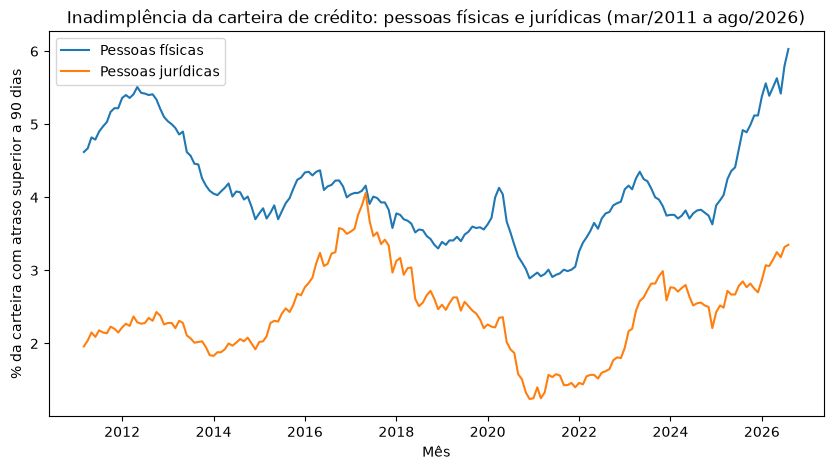

In [45]:
plt.figure(figsize=(10, 5))
plt.plot(q1["data"], q1["pf"], label="Pessoas físicas")
plt.plot(q1["data"], q1["pj"], label="Pessoas jurídicas")
plt.title("Inadimplência da carteira de crédito: pessoas físicas e jurídicas (mar/2011 a ago/2026)")
plt.xlabel("Mês")
plt.ylabel("% da carteira com atraso superior a 90 dias")
plt.legend()
plt.show()

*Fonte: Banco Central do Brasil, SGS (séries 21084 e 21083).*

In [46]:
for coluna in ["pf", "pj"]:
    data_max = q1.loc[q1[coluna].idxmax(), "data"].date()
    data_min = q1.loc[q1[coluna].idxmin(), "data"].date()
    print(coluna, "máximo:", data_max, q1[coluna].max(), "| mínimo:", data_min, q1[coluna].min())

pf máximo: 2026-08-01 6.03 | mínimo: 2020-12-01 2.89
pj máximo: 2017-05-01 4.06 | mínimo: 2020-12-01 1.24


In [47]:
inicio = q1.loc[q1["data"] == "2024-12-01"].iloc[0]
fim = q1.iloc[-1]

for coluna in ["pf", "pj"]:
    pp = fim[coluna] - inicio[coluna]
    relativa = pp / inicio[coluna] * 100
    print(coluna, round(pp, 2), "p.p.", round(relativa, 1), "%")

pf 2.4 p.p. 66.1 %
pj 1.14 p.p. 51.6 %


**Leitura do gráfico**

- **Níveis:** a inadimplência de pessoas físicas é maior que a de pessoas jurídicas durante quase todo o período. Em 2011 ela é mais que o dobro (cerca de 4,6% contra 2,0%), e as duas séries só quase se igualam em meados de 2017.
- **2012–2014:** a PF começa alta (cerca de 5,5% em 2012) e cai até 2014, enquanto a PJ fica estável em cerca de 2%.
- **2015–2017:** a PJ sobe de cerca de 1,9% para **4,06% em maio de 2017**, o seu máximo. A PF sobe menos (de cerca de 3,7% para 4,3% em 2016) e depois se estabiliza.

- **Pandemia:** após uma alta pontual da PF em abril de 2020, as duas séries **caem** e chegam ao mínimo em **dezembro de 2020**: 2,89% para PF e 1,24% para PJ.
- **2021–2023:** as duas voltam a subir, e a PF recua em 2023.
- **A partir de 2025:** alta forte nas duas séries. A PF chega a **6,03% em agosto de 2026**, o maior valor de toda a série, e a PJ a cerca de 3,3%. Em pontos percentuais, a PF sobe cerca de 2,4 em menos de dois anos.

- **Pontos percentuais e variação relativa.** Uma mudança na taxa de inadimplência pode ser medida de duas formas, e elas contam histórias diferentes. Tomando como ponto de partida o vale de dez/2024, a inadimplência de pessoas físicas subiu 2,4 pontos percentuais (de 3,63% para 6,03%), o que equivale a um aumento relativo de 66%. A de pessoas jurídicas subiu 1,14 ponto percentual (de 2,21% para 3,35%), um aumento relativo de 52%. Em pontos percentuais, a alta da PF é mais que o dobro da PJ, mas em termos relativos a diferença entre os dois grupos é bem menor. Neste trabalho, "pontos percentuais" indica a diferença absoluta entre duas taxas, e "variação relativa" indica quanto a taxa cresceu em relação ao valor de partida.

**Possíveis explicações (hipóteses, que este gráfico não testa)**

- **A alta de 2015–2017**, mais forte na PJ, é compatível com os efeitos da recessão de 2014–2016: dívidas contraídas antes da crise só viram atraso de mais de 90 dias depois de alguns meses. A pergunta 5 trata dessa defasagem.

- **A queda na pandemia** pode refletir as medidas de renegociação e prorrogação de parcelas adotadas na época, que seguraram os atrasos. Entretanto, como será mostrado futuramente, durante o ano de 2020, o BOCOM , que ainda não tinha sua autonomia formal sancionada, decidiu por manter a Taxa Selic em 2% , o que pode ter reduzido significativamente a inadimplência por conta da taxa de juros baixa.
[Fonte](https://www.cnnbrasil.com.br/economia/seu-bolso/meu-dinheiro/repactuacao-de-dividas-soma-187-milhoes-de-contratos-na-pandemia-diz-febraban/)

- **A alta recente** coincide com o período em que a Selic esteve em níveis elevados. A relação entre as duas séries é o tema das perguntas 5 e 6.

**Limitação:** a série mede a proporção do saldo da carteira em atraso, e não o número de pessoas ou empresas inadimplentes.

## Pergunta 2: quais modalidades de crédito têm mais inadimplência, e esse ranking é estável ao longo do tempo?

**Hipótese:** Imaginamos que modalidades de crédito como cartão de crédito rotativo, financiamento para veículos/moradia, crédito consignado sejam as mais populares, entretanto, nossa hipótese é de que modalidades com juros mais alto e sem garantia , como cartão de crédito, crédito pessoal sem consignação e cheque especial estejam mais presentes sob a óptica da inadimplência. Por exemplo, o crédito consignado público, voltado para servidores públicos, aposentados e pensionistas do INSS, já vem descontado no pagamento, então a inadimplência tende a ser menor

**Dados:** tabela `scr` (SCR.data resumida), de jul/2012 a ago/2026, restrita a pessoas físicas. O nível de análise é a submodalidade, identificada junto com a modalidade, porque o mesmo nome de submodalidade aparece sob modalidades diferentes.

In [48]:
q2_base = scr[scr["cliente"] == "PF"]

produtos = q2_base.groupby(["modalidade", "submodalidade"])[["carteira_ativa", "carteira_inadimplencia"]].sum()
produtos["taxa"] = produtos["carteira_inadimplencia"] / produtos["carteira_ativa"] * 100
produtos["participacao"] = produtos["carteira_ativa"] / produtos["carteira_ativa"].sum() * 100

produtos.sort_values("participacao", ascending=False).round(2).head(15)

,,carteira_ativa,carteira_inadimplencia,taxa,participacao
modalidade,submodalidade,,,,
Financiamentos imobiliários,Financiamento habitacional - SFH,1.091291e+14,1.691616e+12,1.55,27.20
Empréstimos,Crédito pessoal - com consignação em folha de pagam.,7.262012e+13,1.876010e+12,2.58,18.10
Outros créditos,Cartão de crédito - compra à vista e parcelado lojista,4.026516e+13,1.370295e+10,0.03,10.04
Financiamentos,Aquisição de bens - veículos automotores,3.918078e+13,1.913609e+12,4.88,9.76
Financiamentos rurais (ex-financiamentos rurais e agroindustriais),Investimento,3.225765e+13,6.075813e+11,1.88,8.04
Empréstimos,Crédito pessoal - sem consignação em folha de pagam.,2.900771e+13,2.432073e+12,8.38,7.23
Financiamentos rurais (ex-financiamentos rurais e agroindustriais),Custeio,2.304828e+13,5.169399e+11,2.24,5.74
Financiamentos imobiliários,Financiamento habitacional  exceto SFH,1.298780e+13,1.711482e+11,1.32,3.24
Empréstimos,Outros empréstimos,9.961176e+12,1.625575e+12,16.32,2.48


 Vamos analisar melhor a submodalidade "Cartão de Crédito- não migrado", que aparece com uma taxa de inadimplência altíssima

In [49]:
nao_migrado = q2_base[q2_base["submodalidade"] == "Cartão de crédito - não migrado"]
nm = nao_migrado.groupby("mes")[["carteira_ativa", "carteira_inadimplencia"]].sum()
nm["taxa"] = nm["carteira_inadimplencia"] / nm["carteira_ativa"] * 100

print(nm.shape)
print(nm.head())
print(nm.tail())

(112, 3)
            carteira_ativa  carteira_inadimplencia       taxa
mes                                                          
2017-05-01    2.367833e+09            1.560523e+09  65.905083
2017-06-01    1.422574e+10            1.104884e+10  77.667933
2017-07-01    1.499624e+10            1.183882e+10  78.945251
2017-08-01    1.446749e+10            1.162902e+10  80.380404
2017-09-01    1.651819e+10            1.243407e+10  75.275002
            carteira_ativa  carteira_inadimplencia       taxa
mes                                                          
2026-04-01    6.874742e+10            5.197559e+10  75.603698
2026-05-01    7.055680e+10            5.479258e+10  77.657404
2026-06-01    6.903851e+10            5.342358e+10  77.382298
2026-07-01    6.994189e+10            5.521816e+10  78.948632
2026-08-01    7.481633e+10            6.011159e+10  80.345541


**Quais produtos entram no ranking:** 

Para que a estabilidade possa ser medida, só entram produtos presentes nos 170 meses do período e com pelo menos 0,5% da carteira de pessoas físicas, para evitar taxas instáveis de produtos pequenos. Esses cortes são uma escolha nossa. A submodalidade "Cartão de crédito - não migrado" fica de fora porque só existe a partir de mai/2017 (112 meses); ela tem taxa muito alta (entre 66% e 80%) e saldo crescente, e a registramos como observação à parte. Não sabemos exatamente o que essa categoria representa.

In [50]:
produtos["meses"] = q2_base.groupby(["modalidade", "submodalidade"])["mes"].nunique()

selecionados = produtos[(produtos["meses"] == 170) & (produtos["participacao"] >= 0.5)]
print(selecionados.shape)
selecionados[["meses", "taxa", "participacao"]].round(2).sort_values("taxa", ascending=False)

(12, 5)


meses  \
modalidade                                         submodalidade                                               
Empréstimos                                        Crédito rotativo vinculado a cartão de crédito        170   
                                                   Outros empréstimos                                    170   
                                                   Cartão de crédito - compra, fatura parcelada ou...    170   
                                                   Crédito pessoal - sem consignação em folha de p...    170   
Financiamentos                                     Aquisição de bens - outros bens                       170   
                                                   Aquisição de bens - veículos automotores              170   
Empréstimos                                        Crédito pessoal - com consignação em folha de p...    170   
Financiamentos rurais  (ex-financiamentos rurai... Custeio                                               170   
                                                   Investimento                                          170   
Financiamentos imobiliários                        Financiamento habitacional - SFH                      170   
                                                   Financiamento habitacional  exceto SFH               170   
Outros créditos                                    Cartão de crédito - compra à vista e parcelado ...    170   

                                                                                                        taxa  \
modalidade                                         submodalidade                                               
Empréstimos                                        Crédito rotativo vinculado a cartão de crédito      21.69   
                                                   Outros empréstimos                                  16.32   
                                                   Cartão de crédito - compra, fatura parcelada ou...   8.60   
                                                   Crédito pessoal - sem consignação em folha de p...   8.38   
Financiamentos                                     Aquisição de bens - outros bens                      7.42   
                                                   Aquisição de bens - veículos automotores             4.88   
Empréstimos                                        Crédito pessoal - com consignação em folha de p...   2.58   
Financiamentos rurais  (ex-financiamentos rurai... Custeio                                              2.24   
                                                   Investimento                                         1.88   
Financiamentos imobiliários                        Financiamento habitacional - SFH                     1.55   
                                                   Financiamento habitacional  exceto SFH              1.32   
Outros créditos                                    Cartão de crédito - compra à vista e parcelado ...   0.03   

                                                                                                       participacao  
modalidade                                         submodalidade                                                     
Empréstimos                                        Crédito rotativo vinculado a cartão de crédito              1.03  
                                                   Outros empréstimos                                          2.48  
                                                   Cartão de crédito - compra, fatura parcelada ou...          1.53  
                                                   Crédito pessoal - sem consignação em folha de p...          7.23  
Financiamentos                                     Aquisição de bens - outros bens                             0.58  
                                                   Aquisição de bens - veículos automotores                    9.76  
Empréstimos          

Após rodarmos a céula anterior, percebemos que o cheque especial não estaria incluso na análise por não aparecer nos 170 meses, como essa submodalidade é uma das mais populares no Brasil, decidimos rodar a célula seguinte para vermos se poderia ter acontecido somente uma mudança de nome

In [51]:
periodo = q2_base.groupby(["modalidade", "submodalidade"])["mes"].agg(["min", "max", "nunique"])
periodo["participacao"] = produtos["participacao"]

periodo[periodo["nunique"] < 170].sort_values("participacao", ascending=False).head(10)

min  \
modalidade                                         submodalidade                                                   
Empréstimos                                        Cheque especial                                    2014-02-01   
                                                   Cartão de crédito - não migrado                    2017-05-01   
                                                   Home Equity                                        2012-10-01   
                                                   Microcrédito                                       2012-10-01   
                                                   Conta Garantida                                    2014-02-01   
Financiamentos imobiliários                        Financiamento de projeto                           2012-07-01   
Empréstimos                                        Cheque especial e conta garantida                  2012-07-01   
Financiamentos rurais  (ex-financiamentos rurai... Financiamento de projeto                           2012-07-01   
Empréstimos                                        Capital de giro com prazo de vencimento superio... 2014-02-01   
                                                   Capital de giro com teto rotativo                  2017-05-01   

                                                                                                             max  \
modalidade                                         submodalidade                                                   
Empréstimos                                        Cheque especial                                    2026-08-01   
                                                   Cartão de crédito - não migrado                    2026-08-01   
                                                   Home Equity                                        2026-08-01   
                                                   Microcrédito                                       2026-08-01   
                                                   Conta Garantida                                    2026-08-01   
Financiamentos imobiliários                        Financiamento de projeto                           2026-08-01   
Empréstimos                                        Cheque especial e conta garantida                  2014-01-01   
Financiamentos rurais  (ex-financiamentos rurai... Financiamento de projeto                           2019-01-01   
Empréstimos                                        Capital de giro com prazo de vencimento superio... 2026-08-01   
                                                   Capital de giro com teto rotativo                  2026-08-01   

                                                                                                       nunique  \
modalidade                                         submodalidade                                                 
Empréstimos                                        Cheque especial                                         151   
                                                   Cartão de crédito - não migrado                         112   
                                                   Home Equity                                             167   
                                                   Microcrédito                                            167   
                                                   Conta Garantida                                         151   
Financiamentos imobiliários                        Financiamento de projeto                                155   
Empréstimos                                        Cheque especial e conta garantida                        19   
Financiamentos rurais  (ex-financiamentos rurai... Financiamento de projeto                                 79   
Empréstimos                                        Capital de giro com prazo de vencimento superio...      151   
                                                   Capital de giro co

Nossa suspeita se confirmou, cheque especial estava com 2 nomes diferentes: "Cheque especial" e "Cheque especial e conta garantida", como ambos juntos somam exatamente 170 meses, fica claro que correnspondem a mesma submodalidade.Logo devemos utilizar a próxima célula como padronização e refazer o filtro de análise

In [52]:
q2_base = scr[scr["cliente"] == "PF"].copy()
q2_base["submodalidade"] = q2_base["submodalidade"].replace({
    "Cheque especial": "Cheque especial e conta garantida",
    "Conta Garantida": "Cheque especial e conta garantida",
})

produtos = q2_base.groupby(["modalidade", "submodalidade"])[["carteira_ativa", "carteira_inadimplencia"]].sum()
produtos["taxa"] = produtos["carteira_inadimplencia"] / produtos["carteira_ativa"] * 100
produtos["participacao"] = produtos["carteira_ativa"] / produtos["carteira_ativa"].sum() * 100
produtos["meses"] = q2_base.groupby(["modalidade", "submodalidade"])["mes"].nunique()

selecionados = produtos[(produtos["meses"] >= 170) & (produtos["participacao"] >= 0.5)]
print(selecionados.shape)
selecionados[["meses", "taxa", "participacao"]].round(2).sort_values("taxa", ascending=False)

(13, 5)


meses  \
modalidade                                         submodalidade                                               
Empréstimos                                        Crédito rotativo vinculado a cartão de crédito        170   
                                                   Outros empréstimos                                    170   
                                                   Cheque especial e conta garantida                     170   
                                                   Cartão de crédito - compra, fatura parcelada ou...    170   
                                                   Crédito pessoal - sem consignação em folha de p...    170   
Financiamentos                                     Aquisição de bens - outros bens                       170   
                                                   Aquisição de bens - veículos automotores              170   
Empréstimos                                        Crédito pessoal - com consignação em folha de p...    170   
Financiamentos rurais  (ex-financiamentos rurai... Custeio                                               170   
                                                   Investimento                                          170   
Financiamentos imobiliários                        Financiamento habitacional - SFH                      170   
                                                   Financiamento habitacional  exceto SFH               170   
Outros créditos                                    Cartão de crédito - compra à vista e parcelado ...    170   

                                                                                                        taxa  \
modalidade                                         submodalidade                                               
Empréstimos                                        Crédito rotativo vinculado a cartão de crédito      21.69   
                                                   Outros empréstimos                                  16.32   
                                                   Cheque especial e conta garantida                   12.10   
                                                   Cartão de crédito - compra, fatura parcelada ou...   8.60   
                                                   Crédito pessoal - sem consignação em folha de p...   8.38   
Financiamentos                                     Aquisição de bens - outros bens                      7.42   
                                                   Aquisição de bens - veículos automotores             4.88   
Empréstimos                                        Crédito pessoal - com consignação em folha de p...   2.58   
Financiamentos rurais  (ex-financiamentos rurai... Custeio                                              2.24   
                                                   Investimento                                         1.88   
Financiamentos imobiliários                        Financiamento habitacional - SFH                     1.55   
                                                   Financiamento habitacional  exceto SFH              1.32   
Outros créditos                                    Cartão de crédito - compra à vista e parcelado ...   0.03   

                                                                                                       participacao  
modalidade                                         submodalidade                                                     
Empréstimos                                        Crédito rotativo vinculado a cartão de crédito              1.03  
                                                   Outros empréstimos                                          2.48  
                                                   Cheque especial e conta garantida                           1.20  
                                                   Cartão de crédito - compra, fatura parcelada ou...          1.53  
                                 

**Taxa de cada produto por ano:** 

Para medir a estabilidade do ranking, calculamos a taxa de inadimplência de cada um dos 13 produtos selecionados em cada ano: somamos a carteira e a inadimplência dos meses do ano e dividimos uma pela outra (soma sobre soma). A tabela resultante tem um ano por linha e um produto por coluna. Os anos de 2012 (jul a dez) e 2026 (jan a ago) são parciais.

In [53]:
q2_sel = q2_base.merge(selecionados.reset_index()[["modalidade", "submodalidade"]], on=["modalidade", "submodalidade"])
q2_sel["ano"] = q2_sel["mes"].dt.year

anual = q2_sel.groupby(["ano", "submodalidade"])[["carteira_ativa", "carteira_inadimplencia"]].sum()
anual["taxa"] = anual["carteira_inadimplencia"] / anual["carteira_ativa"] * 100

taxa_anual = anual["taxa"].unstack("submodalidade")
print(taxa_anual.shape)
taxa_anual.round(1)

(15, 13)


submodalidade,Aquisição de bens - outros bens,Aquisição de bens - veículos automotores,Cartão de crédito - compra à vista e parcelado lojista,"Cartão de crédito - compra, fatura parcelada ou saque financiado pela instituição financeira emitente do cartão",Cheque especial e conta garantida,Crédito pessoal - com consignação em folha de pagam.,Crédito pessoal - sem consignação em folha de pagam.,Crédito rotativo vinculado a cartão de crédito,Custeio,Financiamento habitacional - SFH,Financiamento habitacional  exceto SFH,Investimento,Outros empréstimos
ano,,,,,,,,,,,,,
2012,8.9,6.9,0.0,6.5,14.5,2.7,10.9,41.1,0.7,1.3,1.5,0.7,16.6
2013,7.4,6.1,0.0,3.2,12.9,2.8,9.5,37.9,0.9,1.5,1.1,0.8,16.9
2014,11.4,5.0,0.0,0.1,11.9,2.7,8.8,36.0,1.0,1.6,1.3,0.6,17.6
2015,14.7,4.3,0.0,0.1,12.4,2.4,8.9,37.7,1.5,1.7,1.7,0.8,17.1
2016,14.9,4.9,0.0,0.1,13.7,2.4,10.3,36.9,1.9,1.7,2.1,1.4,19.2
2017,13.3,4.4,0.0,1.4,13.5,2.5,9.3,24.8,1.8,1.6,1.9,2.0,18.7
2018,9.6,3.7,0.0,3.7,12.2,2.5,8.6,5.3,1.6,1.6,1.7,2.0,17.1
2019,8.7,3.5,0.0,4.9,12.7,2.4,8.5,6.0,1.6,1.6,1.6,1.8,15.7
2020,6.6,3.8,0.0,4.9,14.0,2.5,7.8,8.8,1.3,1.6,1.6,1.5,11.8


Como podemos ver, fica de certa forma difícil ler cada submodalidade devido ao tamanho de cada frase, então vamos reescrevê-las a fim de facilitar a legibilidade

In [56]:
nomes = {
    "Aquisição de bens - outros bens": "Outros bens",
    "Aquisição de bens - veículos automotores": "Veículos",
    "Cartão de crédito - compra, fatura parcelada ou saque financiado pela instituição financeira emitente do cartão": "Cartão parcelado (emissor)",
    "Cheque especial e conta garantida": "Cheque especial",
    "Crédito pessoal - com consignação em folha de pagam.": "Consignado",
    "Crédito pessoal - sem consignação em folha de pagam.": "Pessoal sem consignação",
    "Crédito rotativo vinculado a cartão de crédito": "Cartão rotativo",
    "Custeio": "Rural - custeio",
    "Investimento": "Rural - investimento",
    "Financiamento habitacional - SFH": "Habitacional SFH",
    "Outros empréstimos": "Outros empréstimos",
}

In [57]:
taxa_curta = taxa_anual.rename(columns=nomes)
taxa_curta = taxa_curta.rename(columns=lambda c: "Cartão à vista/lojista" if "lojista" in c else c)
taxa_curta = taxa_curta.rename(columns=lambda c: "Habitacional exceto SFH" if "exceto SFH" in c else c)

ordem = taxa_curta.mean().sort_values(ascending=False).index
taxa_curta[ordem].T.round(1)

ano,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
submodalidade,,,,,,,,,,,,,,,
Cartão rotativo,41.1,37.9,36.0,37.7,36.9,24.8,5.3,6.0,8.8,7.6,9.8,14.7,15.2,14.2,19.1
Outros empréstimos,16.6,16.9,17.6,17.1,19.2,18.7,17.1,15.7,11.8,13.9,14.9,16.3,16.5,17.4,18.1
Cheque especial,14.5,12.9,11.9,12.4,13.7,13.5,12.2,12.7,14.0,9.8,10.1,10.7,10.1,12.0,13.7
Pessoal sem consignação,10.9,9.5,8.8,8.9,10.3,9.3,8.6,8.5,7.8,5.4,7.3,8.0,6.9,8.8,10.8
Outros bens,8.9,7.4,11.4,14.7,14.9,13.3,9.6,8.7,6.6,3.6,4.1,5.0,4.8,6.9,8.8
Cartão parcelado (emissor),6.5,3.2,0.1,0.1,0.1,1.4,3.7,4.9,4.9,5.1,6.0,9.3,10.8,11.7,14.8
Veículos,6.9,6.1,5.0,4.3,4.9,4.4,3.7,3.5,3.8,3.5,4.9,5.6,4.7,5.3,6.4
Consignado,2.7,2.8,2.7,2.4,2.4,2.5,2.5,2.4,2.5,2.5,2.5,2.4,2.5,2.7,3.4
Rural - custeio,0.7,0.9,1.0,1.5,1.9,1.8,1.6,1.6,1.3,0.6,0.4,0.6,1.5,4.2,8.4


Vamos fazer o ranking por ano das submodalidades com a maior taxa de inadimplência

In [58]:
ranking = taxa_curta.rank(axis=1, ascending=False, method="min").astype(int)
ranking[ordem].T

ano,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
submodalidade,,,,,,,,,,,,,,,
Cartão rotativo,1,1,1,1,1,1,5,5,3,3,3,2,2,2,1
Outros empréstimos,2,2,2,2,2,2,1,1,2,1,1,1,1,1,2
Cheque especial,3,3,3,4,4,3,2,2,1,2,2,3,4,3,4
Pessoal sem consignação,4,4,5,5,5,5,4,4,4,4,4,5,5,5,5
Outros bens,5,5,4,3,3,4,3,3,5,6,7,7,6,6,6
Cartão parcelado (emissor),7,7,12,12,12,12,7,6,6,5,5,4,3,4,3
Veículos,6,6,6,6,6,6,6,7,7,7,6,6,7,7,8
Consignado,8,8,7,7,7,7,8,8,8,8,8,8,8,10,10
Rural - custeio,12,11,10,10,9,10,12,10,12,12,12,11,9,8,7


Como na pergunta queremos saber a estabilidade da ordem de inadimplência, precisávamos de um método para fazer essa comparação. Não sabíamos qual metódo usar, então após pesquisar na internet e utilizar o claude, chegamos a conclusão de que a melhor forma de comparar seria a partir da correlação de Spearman e depois comparando a um referencial (usaremos o ano de 2012), em que se o ranking for estável, teremos valores próximos de 1

In [59]:
estabilidade = pd.Series(
    [taxa_curta.iloc[i].corr(taxa_curta.iloc[i + 1], method="spearman") for i in range(len(taxa_curta) - 1)],
    index=taxa_curta.index[1:],
)
estabilidade.round(2)

ano
2013    0.99
2014    0.91
2015    0.99
2016    0.99
2017    0.96
2018    0.86
2019    0.98
2020    0.93
2021    0.98
2022    0.99
2023    0.98
2024    0.96
2025    0.97
2026    0.98
dtype: float64

In [60]:
referencia = taxa_curta.loc[2012]
contra_2012 = taxa_curta.apply(lambda linha: linha.corr(referencia, method="spearman"), axis=1)
contra_2012.round(2)

ano
2012    1.00
2013    0.99
2014    0.90
2015    0.90
2016    0.88
2017    0.88
2018    0.92
2019    0.89
2020    0.97
2021    0.96
2022    0.96
2023    0.95
2024    0.89
2025    0.87
2026    0.82
dtype: float64

**Resultado da pergunta 2**

**(a) Quais modalidades têm mais inadimplência:** Considerando o período inteiro e os 13 produtos selecionados, os de maior taxa são o crédito rotativo do cartão (21,7%), "outros empréstimos" (16,3%), o cheque especial (12,1%), o cartão parcelado pelo emissor (8,6%) e o crédito pessoal sem consignação (8,4%). Os de menor taxa são os financiamentos habitacionais (1,3% e 1,6%), os financiamentos rurais (1,9% e 2,2%) e o consignado (2,6%). Isso confirma a nossa hipótese: crédito caro e sem garantia lidera a inadimplência, e crédito com garantia ou desconto em folha fica entre os menores. Uma ressalva é que "cartão de crédito" não é um produto só: o rotativo tem a maior taxa, e o cartão à vista/lojista tem taxa próxima de zero.

**(b) Estabilidade do ranking:** O ranking é muito estável de um ano para o outro: a correlação de Spearman entre anos consecutivos fica entre 0,86 e 0,99. Os cinco produtos de maior taxa ocupam as cinco primeiras posições em quase todos os anos até 2022, e os financiamentos com garantia ficam sempre na metade inferior. Comparado com 2012, o ranking se afasta aos poucos no fim do período (correlação de 0,82 em 2026), principalmente porque o cartão parcelado pelo emissor sobe do 12º para o 3º lugar e o crédito rural sobe do 12º para o 7º.

**Ressalvas:**
- A queda da taxa do rotativo em 2017–2018 (de 37% para 5%) coincide com o surgimento da categoria "cartão não migrado" e com a mudança nas regras do rotativo; é possível que parte da mudança seja reclassificação, e não mudança de comportamento. Não verificamos isso.
- "Outros empréstimos" é uma categoria residual, e não sabemos o que ela contém.
- A taxa próxima de zero do cartão à vista/lojista provavelmente é estrutural (o atraso aparece em outras categorias de cartão), e ela não deve ser lida como o produto mais seguro.
- Posições vizinhas na parte baixa da tabela têm taxas quase idênticas (1,5% a 2%), então trocas de uma ou duas posições ali não são relevantes.
- 2012 (jul–dez) e 2026 (jan–ago) são anos parciais.
- Só pessoas físicas; produtos presentes nos 170 meses e com ao menos 0,5% da carteira.

## Pergunta 3: O spread de pessoas físicas é sistematicamente diferente do de pessoas jurídicas, e essa diferença mudou?

**Hipótese:** Imaginamos que o spread de crédito para pessoas físicas seja sistematicamente maior do que para pessoas jurídicas no Brasil, devido às diferenças no risco de inadimplência, nas garantias oferecidas e no poder de negociação dos tomadores. Nossa hipótese é que essa diferença tenha sofrido oscilações ao longo do período de março de 2011 a agosto de 2026, especialmente em momentos de recessão econômica, como a crise de 2015–2016, e de instabilidade, como a pandemia de Covid-19 e o período posterior. Acreditamos que esses acontecimentos tenham afetado de maneiras distintas as condições de crédito para famílias e empresas, alterando a percepção de risco dos bancos e, consequentemente, os spreads cobrados de cada grupo. Entretanto, esperamos que o spread das pessoas físicas tenha permanecido superior ao das pessoas jurídicas durante a maior parte do período analisado.

**Dados**: spread_pj 20784 (PJ) e spread_pf 20785 (PF) mensal, de Março de 2011 a Agosto de 2026

In [64]:
pf = pd.read_csv("data/sgs/spread_pf_20785.csv")
pj = pd.read_csv("data/sgs/spread_pj_20784.csv")

print("Pessoas físicas:")
display(pf.head())

print("Pessoas jurídicas:")
display(pj.head())

Pessoas físicas:


,data,valor
0,01/03/2011,26.06
1,01/04/2011,26.66
2,01/05/2011,26.49
3,01/06/2011,26.30
4,01/07/2011,26.34


Pessoas jurídicas:


,data,valor
0,01/03/2011,10.22
1,01/04/2011,10.72
2,01/05/2011,10.72
3,01/06/2011,10.50
4,01/07/2011,10.39


In [72]:
pf = pd.read_csv("data/sgs/spread_pf_20785.csv")
print(pf.shape, pf["data"].iloc[0], pf["data"].iloc[-1])

(186, 2) 01/03/2011 01/08/2026


**O que fizemos:** lemos spread_pf_20785.csv & spread_pj_20784.csv e verificamos se foram importados corretamente

In [65]:
pf["data"] = pd.to_datetime(pf["data"], dayfirst=True)
pj["data"] = pd.to_datetime(pj["data"], dayfirst=True)

pf = pf.rename(columns={"valor": "spread_pf"})
pj = pj.rename(columns={"valor": "spread_pj"})

q3 = pd.merge(
    pf,
    pj,
    on="data",
    how="inner",
    validate="one_to_one"
).sort_values("data").reset_index(drop=True)

q3["diferenca"] = q3["spread_pf"] - q3["spread_pj"]

print(f"Período analisado: {q3['data'].min():%m/%Y} a {q3['data'].max():%m/%Y}")
print(f"Número de observações: {len(q3)}")

display(q3.head())

Período analisado: 03/2011 a 08/2026
Número de observações: 186


,data,spread_pf,spread_pj,diferenca
0,2011-03-01,26.06,10.22,15.84
1,2011-04-01,26.66,10.72,15.94
2,2011-05-01,26.49,10.72,15.77
3,2011-06-01,26.30,10.50,15.80
4,2011-07-01,26.34,10.39,15.95


**O que fizemos:** convertemos as datas para o formato adequado, juntamos as duas séries temporais e calculamos a diferença entre os spreads de pessoas físicas e jurídicas.

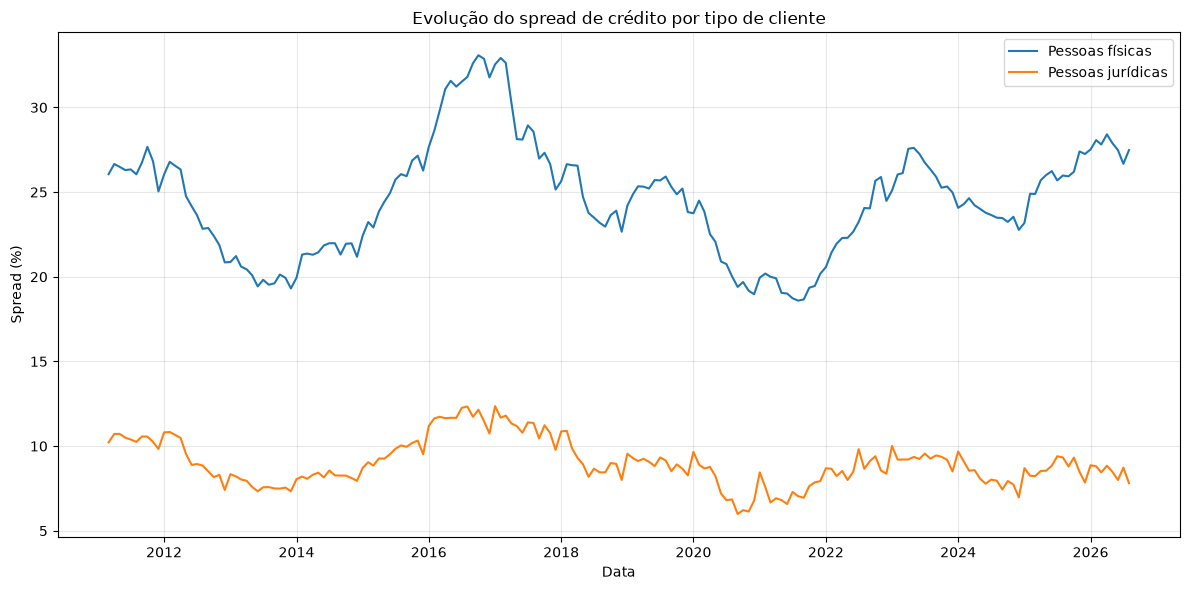

In [66]:
plt.figure(figsize=(12, 6))

plt.plot(q3["data"], q3["spread_pf"], label="Pessoas físicas")
plt.plot(q3["data"], q3["spread_pj"], label="Pessoas jurídicas")

plt.title("Evolução do spread de crédito por tipo de cliente")
plt.xlabel("Data")
plt.ylabel("Spread (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**O que fizemos:** construímos um gráfico com as duas séries mensais, entre março de 2011 e agosto de 2026.

In [67]:
estatisticas_q3 = q3[
    ["spread_pf", "spread_pj", "diferenca"]
].agg(["mean", "median", "std", "min", "max"])

display(estatisticas_q3.round(2))

,spread_pf,spread_pj,diferenca
mean,24.55,9.02,15.53
median,24.74,8.82,15.69
std,3.35,1.36,2.30
min,18.59,5.99,11.44
max,33.08,12.36,21.40


**O que fizemos:** calculamos medidas de tendência central e dispersão para os spreads e para a diferença entre eles.

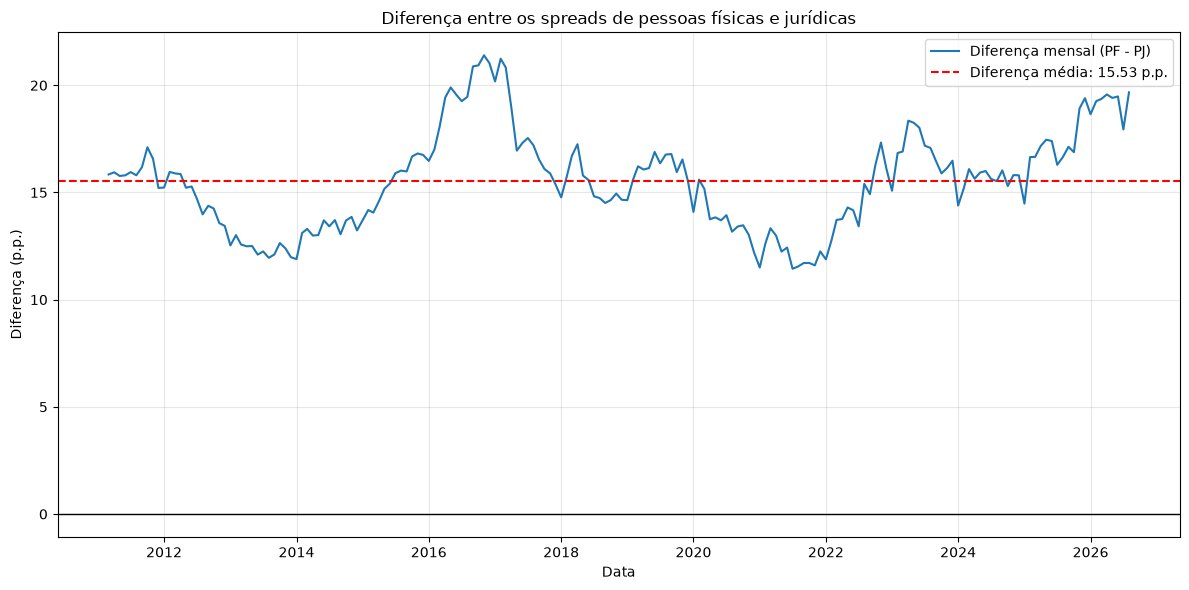

In [68]:
diferenca_media = q3["diferenca"].mean()

plt.figure(figsize=(12, 6))

plt.plot(
    q3["data"],
    q3["diferenca"],
    label="Diferença mensal (PF - PJ)"
)

plt.axhline(
    diferenca_media,
    color="red",
    linestyle="--",
    label=f"Diferença média: {diferenca_media:.2f} p.p."
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Diferença entre os spreads de pessoas físicas e jurídicas")
plt.xlabel("Data")
plt.ylabel("Diferença (p.p.)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**O que fizemos:** representamos a diferença mensal entre os spreads e adicionamos uma linha correspondente à diferença média do período.

In [69]:
modelo_media = sm.OLS(
    q3["diferenca"],
    pd.DataFrame({"const": 1}, index=q3.index)
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12}
)

intervalo_media = modelo_media.conf_int().loc["const"]

print(f"Diferença média: {modelo_media.params['const']:.2f} p.p.")
print(f"Intervalo de confiança de 95%: "
      f"[{intervalo_media.iloc[0]:.2f}, {intervalo_media.iloc[1]:.2f}] p.p.")
print(f"Valor-p: {modelo_media.pvalues['const']:.6g}")

Diferença média: 15.53 p.p.
Intervalo de confiança de 95%: [14.48, 16.58] p.p.
Valor-p: 1.69558e-185


**O que fizemos:** estimamos a diferença média e seu intervalo de confiança de 95%, utilizando erros-padrão robustos à heterocedasticidade e à autocorrelação (HAC), com 12 defasagens.

In [70]:
q3["tempo_anos"] = (
    (q3["data"] - q3["data"].min()).dt.days / 365.25
)

modelo_tendencia = sm.OLS(
    q3["diferenca"],
    sm.add_constant(q3["tempo_anos"])
).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 12}
)

intervalo_tendencia = modelo_tendencia.conf_int().loc["tempo_anos"]

print(f"Tendência estimada: "
      f"{modelo_tendencia.params['tempo_anos']:.3f} p.p./ano")
print(f"Intervalo de confiança de 95%: "
      f"[{intervalo_tendencia.iloc[0]:.3f}, "
      f"{intervalo_tendencia.iloc[1]:.3f}] p.p./ano")
print(f"Valor-p: {modelo_tendencia.pvalues['tempo_anos']:.4f}")

print(modelo_tendencia.summary())

Tendência estimada: 0.119 p.p./ano
Intervalo de confiança de 95%: [-0.066, 0.303] p.p./ano
Valor-p: 0.2068
                            OLS Regression Results                            
Dep. Variable:              diferenca   R-squared:                       0.054
Model:                            OLS   Adj. R-squared:                  0.049
Method:                 Least Squares   F-statistic:                     1.594
Date:                Wed, 28 Oct 2026   Prob (F-statistic):              0.208
Time:                        22:09:56   Log-Likelihood:                -412.97
No. Observations:                 186   AIC:                             829.9
Df Residuals:                     184   BIC:                             836.4
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------

**O que fizemos:** estimamos uma regressão linear da diferença entre os spreads em função do tempo, também utilizando erros-padrão HAC.

In [71]:
ponto_divisao = len(q3) // 2

primeira_metade = q3.iloc[:ponto_divisao]
segunda_metade = q3.iloc[ponto_divisao:]

media_primeira = primeira_metade["diferenca"].mean()
media_segunda = segunda_metade["diferenca"].mean()

print(
    f"Primeira metade "
    f"({primeira_metade['data'].min():%m/%Y} a "
    f"{primeira_metade['data'].max():%m/%Y}): "
    f"{media_primeira:.2f} p.p."
)

print(
    f"Segunda metade "
    f"({segunda_metade['data'].min():%m/%Y} a "
    f"{segunda_metade['data'].max():%m/%Y}): "
    f"{media_segunda:.2f} p.p."
)

print(
    f"Variação entre as médias: "
    f"{media_segunda - media_primeira:.2f} p.p."
)

Primeira metade (03/2011 a 11/2018): 15.57 p.p.
Segunda metade (12/2018 a 08/2026): 15.50 p.p.
Variação entre as médias: -0.07 p.p.


**O que fizemos:** comparamos a diferença média entre os spreads na primeira e na segunda metade da série.

**Resultado da pergunta 3:**

Os resultados indicam que o spread de crédito das pessoas físicas foi sistematicamente superior ao das pessoas jurídicas durante o período analisado. A diferença média foi de aproximadamente 15,53 pontos percentuais, com spread médio de 24,55% para pessoas físicas e 9,02% para pessoas jurídicas.

A análise da diferença média, utilizando erros-padrão robustos à autocorrelação e à heterocedasticidade, indica que essa diferença é estatisticamente significativa. Portanto, os dados fornecem evidências de que o spread das pessoas físicas foi, em média, superior ao das pessoas jurídicas entre março de 2011 e agosto de 2026.

Por outro lado, a regressão linear da diferença ao longo do tempo estimou uma tendência positiva de aproximadamente 0,119 ponto percentual por ano, mas sem significância estatística ao nível de 5% (valor-p próximo de 0,207). Assim, não encontramos evidências estatísticas suficientes de uma tendência linear de aumento ou redução da diferença ao longo de todo o período. 

Isso não significa que a diferença tenha permanecido constante. Ela pode ter apresentado oscilações importantes em determinados momentos, mesmo sem uma tendência linear estatisticamente significativa. A comparação entre as duas metades da série também ajuda a avaliar essas variações, mas não substitui testes específicos de mudanças estruturais.

Os resultados são compatíveis com a hipótese inicial de que o spread das pessoas físicas seja superior ao das pessoas jurídicas. Entretanto, a hipótese de que a diferença tenha aumentado ou diminuído sistematicamente ao longo do período não recebeu suporte estatístico suficiente. Por fim, embora diferenças de risco, garantias e poder de negociação possam ajudar a explicar esse comportamento, a análise descritiva não permite estabelecer que esses fatores sejam suas causas diretas.

**Ressalvas da análise:**

Os resultados devem ser interpretados considerando que os dados são séries temporais mensais, cujas observações podem apresentar dependência ao longo do tempo. Embora tenham sido utilizados erros-padrão robustos à heterocedasticidade e à autocorrelação, as conclusões dependem das especificações adotadas no modelo.

Além disso, a ausência de uma tendência linear estatisticamente significativa não implica que a diferença entre os spreads tenha permanecido constante. Oscilações, mudanças abruptas e comportamentos distintos em períodos de crise podem não ser capturados por uma única tendência linear. Por fim, a análise identifica diferenças e associações temporais, mas não permite estabelecer relações causais entre os spreads e fatores como inadimplência, Selic ou condições econômicas.

## Problema 6: O spread sobe na mesma velocidade com que desce quando a Selic muda?

### Definições:
->  Spread bancário: É a diferença entre os juros que o banco paga para captar dinheiro (dos investidores ou da poupança) e os juros que ele cobra ao emprestar esse dinheiro para clientes.
-> Selic: A Taxa Selic é a taxa básica de juros da economia brasileira.

### Resultado hipotético esperado:
-> Como a taxa selic é usada como parâmetro por bancos para geração de emprestimos e para compras de Cerfificados de Depósito Bancário(CDB), acreditamos que existe uma correlação direta entre o spread bancário, tanto para pessoas físicas quanto para pessoas juridicas, com o valor da Taxa Selic. 

Dito isso, vamos utilizar os dados que temos e tentar analisar os gráficos gerados por eles:

In [73]:
selic_api["data"] = pd.to_datetime(selic_api["data"], format="%d/%m/%Y")
selic_mensal = selic_api[selic_api["data"].dt.day == 1].iloc[2:]
print(selic_mensal.shape)
selic_mensal.head()

(186, 2)


,data,valor
59,2011-03-01,11.25
90,2011-04-01,11.75
120,2011-05-01,12.00
151,2011-06-01,12.00
181,2011-07-01,12.25


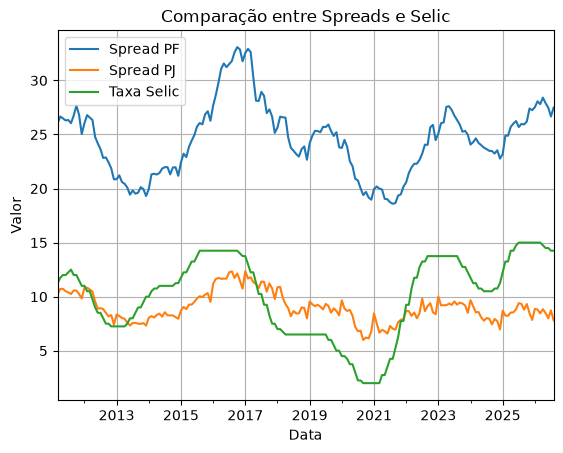

In [74]:
spread_pf_api["data"] = pd.to_datetime(spread_pf_api["data"], format="%d/%m/%Y")
spread_pf_api["valor"] = pd.to_numeric(spread_pf_api["valor"])
spread_pf_api.plot(x="data", y="valor", label="Spread PF")

spread_pj_api["data"] = pd.to_datetime(spread_pj_api["data"], format="%d/%m/%Y")
spread_pj_api["valor"] = pd.to_numeric(spread_pj_api["valor"])
spread_pj_api.plot(x="data", y="valor", label="Spread PJ", ax=plt.gca())

selic_mensal["valor"] = pd.to_numeric(selic_mensal["valor"])
selic_mensal.plot(x="data", y="valor", label="Taxa Selic", ax=plt.gca())

plt.title("Comparação entre Spreads e Selic")
plt.xlabel("Data")
plt.ylabel("Valor")
plt.legend() 
plt.grid(True)

plt.show()

## Resultados

### Relação entre a Taxa Selic e o Spread PF(Pessoas Físicas)

Ao analisar o gráfico, notamos que o Spread bancário, para pessoas físicas, acompanha o crescimento e a queda da taxa Selic com uma variação bem maior do que o Spread bancário para pessoas jurídicas. Porém, com esse gráfico, nós não conseguimos saber exatamente se o Spread sobe com a mesma velocidade com que cai baseado na variação da Selic. Então, vamos analisar a taxa de variação das derivadas:

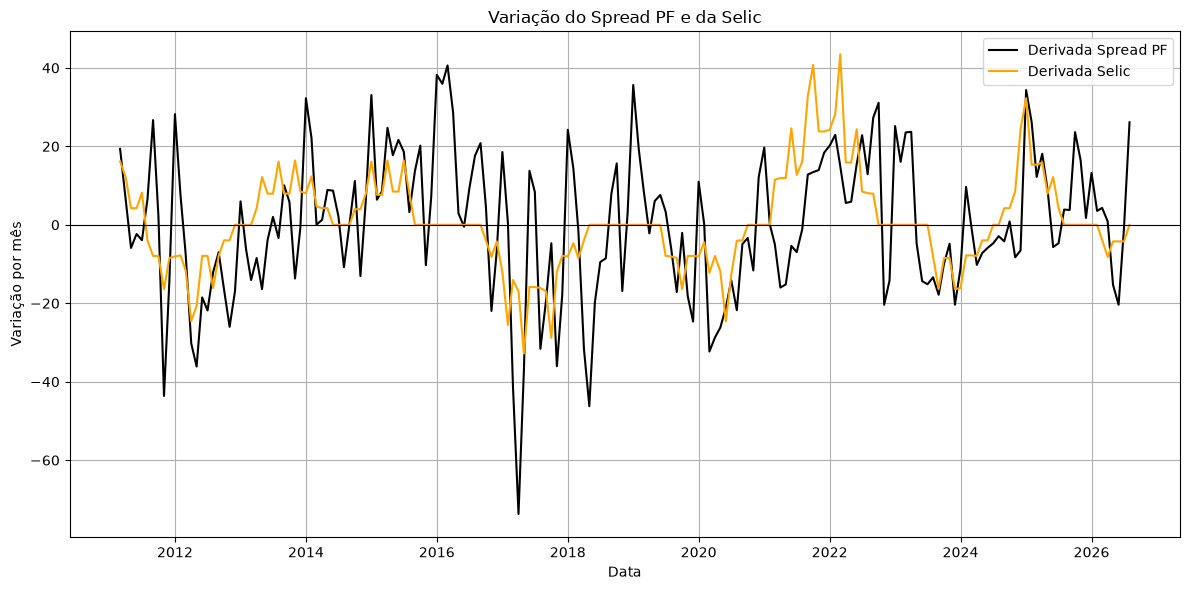

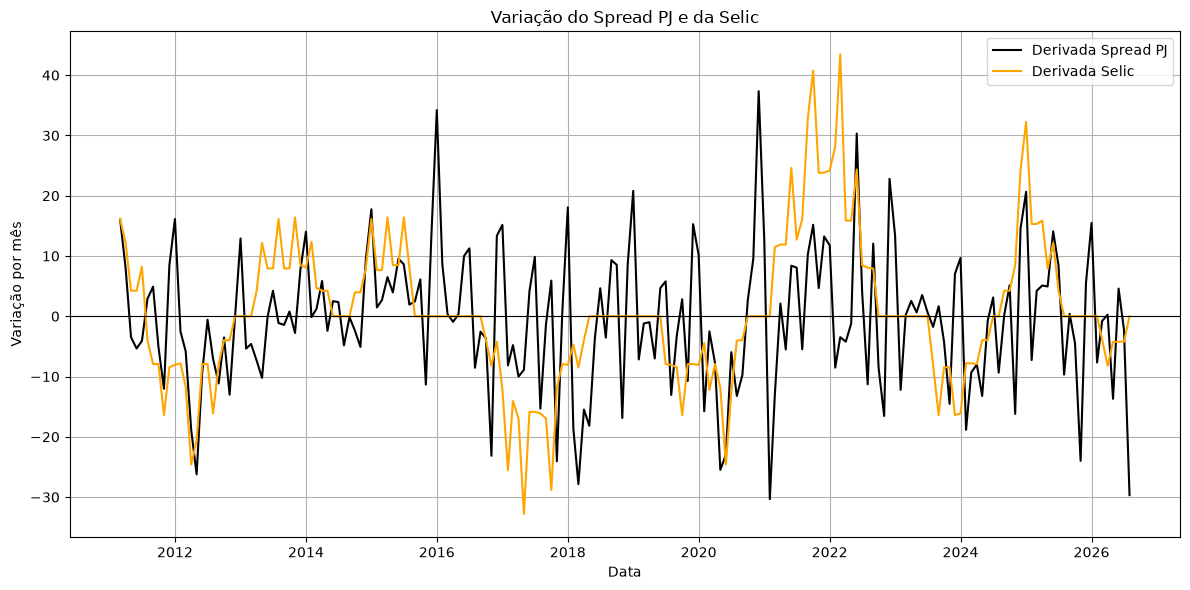

In [75]:
spread_pf_api["derivada"] = np.gradient(
    spread_pf_api["valor"], spread_pf_api["data"].astype("int64") / 86_400_000_000_000
)

spread_pj_api["derivada"] = np.gradient(
    spread_pj_api["valor"], spread_pj_api["data"].astype("int64") / 86_400_000_000_000
)

selic_mensal["derivada"] = np.gradient(
    selic_mensal["valor"], selic_mensal["data"].astype("int64") / 86_400_000_000_000
)

# _______________________________________________________________________________________

plt.figure(figsize=(12, 6))

plt.plot(
    spread_pf_api["data"], spread_pf_api["derivada"], label="Derivada Spread PF", color="black"
)
plt.plot(
    selic_mensal["data"], selic_mensal["derivada"], label="Derivada Selic", color="orange"
)

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Variação do Spread PF e da Selic")
plt.xlabel("Data")
plt.ylabel("Variação por mês")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

# _______________________________________________________________________________________

plt.figure(figsize=(12, 6))

plt.plot(
    spread_pj_api["data"], spread_pj_api["derivada"], label="Derivada Spread PJ", color="black"
)
plt.plot(
    selic_mensal["data"], selic_mensal["derivada"], label="Derivada Selic", color="orange"
)

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Variação do Spread PJ e da Selic")
plt.xlabel("Data")
plt.ylabel("Variação por mês")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

## Taxa de variação do Spread e Selic

A partir desses gráficos, conseguimos entender melhor a relação entre a queda e a subida do spread com a queda e a subida da taxa selic. Esse gráfico é bom para responder a pergunta em um intervalo de um ou dois anos, mas não é tão eficiente para períodos maiores, bem como para toda a amostra. Então, vamos pegar as médias das derivadas para entender, de forma geral, se o spread sobe na mesma velocidade com que desce quando a Selic muda.

In [76]:
derivadas = pd.DataFrame({
    "derivada_selic": selic_mensal["derivada"].values,
    "derivada_spread_pf": spread_pf_api["derivada"].values,
    "derivada_spread_pj": spread_pj_api["derivada"].values,
})

meses_alta_selic  = derivadas[derivadas["derivada_selic"] > 0]
meses_queda_selic = derivadas[derivadas["derivada_selic"] < 0]

colunas_spread = [
    ("derivada_spread_pf", "PF"),
    ("derivada_spread_pj", "PJ"),
]

for coluna_spread, tipo_cliente in colunas_spread:
    resposta_spread_alta = (
        meses_alta_selic[coluna_spread].sum() / meses_alta_selic["derivada_selic"].sum()
    )
    resposta_spread_queda = (
        meses_queda_selic[coluna_spread].sum() / meses_queda_selic["derivada_selic"].sum()
    )
    razao_queda_alta = resposta_spread_queda / resposta_spread_alta

    print(f"{tipo_cliente}: spread varia {resposta_spread_alta:.2f} por unidade de alta da Selic "
          f"e {resposta_spread_queda:.2f} por unidade de queda")
    print(f"  queda/alta = {razao_queda_alta:.2f}")

PF: spread varia 0.52 por unidade de alta da Selic e 0.83 por unidade de queda
  queda/alta = 1.61
PJ: spread varia 0.25 por unidade de alta da Selic e 0.46 por unidade de queda
  queda/alta = 1.84


## Resultado final: Amostra média

Agora estamos prontos para responde a pergunta na amostra geral. Para amostras parciais relativas a um ou dois anos podemos utilizar o gráfico de variação do Spread e a Selic(baseado nas derivadas), porém para uma amostra geral, aquele gráfico não é eficiente. Então, para respondermos a pegunta de forma geral, vamos pegar as taxas "taxa_positiva_pj", "taxa_negativa_pj", "", "" pois elas pegam a taxa de variação do spread tanto positivas quanto negativas e tanto de pj como de pf, e dividem pela variação média positiva e negativa, da taxa Selic. No final, temos a taxa da variação de valores positivos e negativos em relação a Selic e podemos fazer comparações. Fazendo as comparações, obtemos:

-> Para PJ, a taxa de variação negativa, em relação a Selic, é 35% maior que a taxa de variação positiva.

-> Para PF, a taxa de variação negativa, em relação a Selic, é 32% maior que a taxa de variação positiva.

Ou seja, tanto para PJ como para PF, o Spread bancário tente a diminuir mais quando a Selic cai do que aumentar quando a Selic está em crescimento. Logo, percebemos que a relação não é simétrica.